In [ ]:
!pip install -q "flwr[simulation]" scikit-learn pandas numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.7/73.7 MB 14.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 102.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.3/129.3 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.5/66.5 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 80.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.5/310.5 kB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.6/73.6 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 283.6/283.6 kB 22.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.4/47.4 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.2/22.

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np

uploaded = files.upload()

# Automatically get the uploaded filename
filename = next(iter(uploaded.keys()))

# Load the CSV
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

Saving veremi_sample.csv to veremi_sample.csv
Dataset loaded successfully!
Dataset shape: (1000, 30)

First five rows:


,type,sendTime,sender,senderPseudo,messageID,class,posx,posy,posz,posx_n,...,aclz,aclx_n,acly_n,aclz_n,hedx,hedy,hedz,hedx_n,hedy_n,hedz_n
0,4,72002.302942,130137,101301377,422013806,0,266.982401,32.336955,0.0,3.480882,...,0.0,0.000862,0.000862,0.0,-0.102790,0.994703,0.0,20.038218,17.541001,0.0
1,4,72003.302942,130137,101301377,422023410,0,266.827208,34.624145,0.0,3.546261,...,0.0,0.000107,0.001040,0.0,-0.099856,0.995002,0.0,20.441139,14.467283,0.0
2,4,72004.302942,130137,101301377,422032081,0,266.420297,38.836461,0.0,3.544045,...,0.0,0.000172,0.001661,0.0,-0.099856,0.995002,0.0,20.850473,11.941528,0.0
3,4,72005.302942,130137,101301377,422040712,0,268.912026,45.414229,0.0,3.340080,...,0.0,0.000171,0.001654,0.0,-0.100172,0.994970,0.0,21.323229,9.633965,0.0
4,4,72006.302942,130137,101301377,422052949,0,268.242276,53.729986,0.0,3.328872,...,0.0,0.000193,0.001852,0.0,-0.097105,0.995274,0.0,21.788034,7.824555,0.0


In [ ]:
print("Available columns:")
print(df.columns.tolist())

print("\nClass distribution:")
print(df["class"].value_counts(dropna=False))

print("\nNumber of unique senders:")
print(df["sender"].nunique())

print("\nMissing values in selected columns:")
print(df[[
    "posx", "posy", "posz",
    "spdx", "spdy", "spdz",
    "aclx", "acly", "aclz",
    "hedx", "hedy", "hedz", "class"
]].isna().sum())

Available columns:
['type', 'sendTime', 'sender', 'senderPseudo', 'messageID', 'class', 'posx', 'posy', 'posz', 'posx_n', 'posy_n', 'posz_n', 'spdx', 'spdy', 'spdz', 'spdx_n', 'spdy_n', 'spdz_n', 'aclx', 'acly', 'aclz', 'aclx_n', 'acly_n', 'aclz_n', 'hedx', 'hedy', 'hedz', 'hedx_n', 'hedy_n', 'hedz_n']

Class distribution:
class
0     582
15    282
17    136
Name: count, dtype: int64

Number of unique senders:
7

Missing values in selected columns:
posx     0
posy     0
posz     0
spdx     0
spdy     0
spdz     0
aclx     0
acly     0
aclz     0
hedx     0
hedy     0
hedz     0
class    0
dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Numerical features describing vehicle position, speed,
# acceleration, and heading
FEATURES = [
    "posx", "posy", "posz",
    "spdx", "spdy", "spdz",
    "aclx", "acly", "aclz",
    "hedx", "hedy", "hedz"
]

# Keep only the features and target label
data = df[FEATURES + ["class"]].copy()

# Convert invalid numeric values to NaN and remove incomplete rows
data[FEATURES] = data[FEATURES].apply(
    pd.to_numeric, errors="coerce"
)
data["class"] = pd.to_numeric(data["class"], errors="coerce")

data = data.replace([np.inf, -np.inf], np.nan).dropna()
data["class"] = data["class"].astype(int)

# Encode class labels as integers starting from zero
encoder = LabelEncoder()
y = encoder.fit_transform(data["class"])

# Convert feature values to a NumPy array
X = data[FEATURES].to_numpy(dtype=np.float32)

print("Usable samples:", len(X))
print("Classes:", encoder.classes_)
print("Number of classes:", len(encoder.classes_))

# A classifier needs at least two classes for this experiment
if len(encoder.classes_) < 2:
    raise ValueError(
        "Only one class exists in this sample. "
        "Create a representative sample containing at least two classes."
    )

# Split the dataset into training and testing portions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Standardize features using training data only
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

INPUT_SIZE = X_train.shape[1]
NUM_CLASSES = len(encoder.classes_)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Input features:", INPUT_SIZE)
print("Output classes:", NUM_CLASSES)

Usable samples: 1000
Classes: [ 0 15 17]
Number of classes: 3

Training samples: 800
Testing samples: 200
Input features: 12
Output classes: 3


In [ ]:
NUM_CLIENTS = 3

# Shuffle training indices reproducibly
rng = np.random.default_rng(42)
indices = rng.permutation(len(X_train))

# Divide training records between clients
client_indices = np.array_split(indices, NUM_CLIENTS)

client_data = []

for i, idx in enumerate(client_indices):
    x_client = X_train[idx]
    y_client = y_train[idx]

    client_data.append((x_client, y_client))

    print(
        f"Client {i}: {len(x_client)} samples, "
        f"{len(np.unique(y_client))} classes"
    )

Client 0: 267 samples, 3 classes
Client 1: 267 samples, 3 classes
Client 2: 266 samples, 3 classes


In [ ]:
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from collections import OrderedDict

# Force CPU execution; this avoids the CUDA error from earlier
DEVICE = torch.device("cpu")

print("Training device:", DEVICE)


class VeReMiModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(INPUT_SIZE, 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, NUM_CLASSES)
        )

    def forward(self, x):
        return self.network(x)

Training device: cpu


In [ ]:
def get_parameters(model):
    """Convert model parameters to NumPy arrays for Flower."""
    return [
        value.detach().cpu().numpy().copy()
        for value in model.state_dict().values()
    ]


def set_parameters(model, parameters):
    """Load NumPy parameters received from the Flower server."""
    state = OrderedDict(
        (key, torch.tensor(value))
        for key, value in zip(
            model.state_dict().keys(), parameters
        )
    )

    model.load_state_dict(state, strict=True)

In [ ]:
import flwr as fl


class VeReMiClient(fl.client.NumPyClient):

    def __init__(self, cid):
        self.cid = int(cid)

        # Get this client's local training data
        x, y = client_data[self.cid]

        self.x = torch.tensor(x, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

        # CPU only
        self.model = VeReMiModel().to(DEVICE)

    def get_parameters(self, config):
        """Send current model parameters to the server."""
        return get_parameters(self.model)

    def fit(self, parameters, config):
        """Train the local model for one federated round."""

        # Start from the global model received from the server
        set_parameters(self.model, parameters)

        loader = DataLoader(
            TensorDataset(self.x, self.y),
            batch_size=32,
            shuffle=True
        )

        optimizer = torch.optim.SGD(
            self.model.parameters(),
            lr=0.01
        )

        criterion = nn.CrossEntropyLoss()
        self.model.train()

        total_loss = 0.0

        for xb, yb in loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            predictions = self.model(xb)
            loss = criterion(predictions, yb)

            # Calculate gradients and update local parameters
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(yb)

        avg_loss = total_loss / len(self.x)

        print(
            f"Client {self.cid} | "
            f"Training loss: {avg_loss:.4f}"
        )

        # Return updated parameters, number of samples,
        # and training metrics to the server
        return (
            get_parameters(self.model),
            len(self.x),
            {"train_loss": float(avg_loss)}
        )

    def evaluate(self, parameters, config):
        """Evaluate the received global model."""

        set_parameters(self.model, parameters)
        self.model.eval()

        x = torch.tensor(X_test, dtype=torch.float32)
        y = torch.tensor(y_test, dtype=torch.long)

        with torch.no_grad():
            logits = self.model(x.to(DEVICE))
            loss = nn.CrossEntropyLoss()(
                logits, y.to(DEVICE)
            ).item()

            predictions = logits.argmax(dim=1)
            accuracy = (
                predictions == y.to(DEVICE)
            ).float().mean().item()

        return (
            float(loss),
            len(y),
            {"accuracy": float(accuracy)}
        )

In [ ]:
# Initialize the global model
initial_model = VeReMiModel()

# Configure FedAvg
strategy = fl.server.strategy.FedAvg(
    fraction_fit=1.0,
    fraction_evaluate=1.0,

    # All three clients participate in each round
    min_fit_clients=NUM_CLIENTS,
    min_evaluate_clients=NUM_CLIENTS,
    min_available_clients=NUM_CLIENTS,

    # Initial global model parameters
    initial_parameters=fl.common.ndarrays_to_parameters(
        get_parameters(initial_model)
    )
)

print("FedAvg strategy initialized successfully!")

FedAvg strategy initialized successfully!


In [ ]:
def client_fn(cid: str):
    """Create a client for the requested client ID."""
    return VeReMiClient(cid).to_client()


history = fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=NUM_CLIENTS,

    config=fl.server.ServerConfig(
        num_rounds=3
    ),

    strategy=strategy,

    # No GPU allocation
    client_resources={
        "num_cpus": 1,
        "num_gpus": 0
    }
)

print("\nFederated training finished.")

	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

          

(ClientAppActor pid=2485) Client 1 | Training loss: 1.1454


INFO :      aggregate_evaluate: received 3 results and 0 failures
INFO :      
INFO :      [ROUND 3]
INFO :      configure_fit: strategy sampled 3 clients (out of 3)
(ClientAppActor pid=2485) 
(ClientAppActor pid=2485)         
(ClientAppActor pid=2485) 
(ClientAppActor pid=2485)         
(ClientAppActor pid=2484) 
(ClientAppActor pid=2484)         
INFO :      aggregate_fit: received 3 results and 0 failures
INFO :      configure_evaluate: strategy sampled 3 clients (out of 3)
(ClientAppActor pid=2485) 
(ClientAppActor pid=2485)         
(ClientAppActor pid=2485) 
(ClientAppActor pid=2485)         
(ClientAppActor pid=2484) 
(ClientAppActor pid=2484)         
INFO :      aggregate_evaluate: received 3 results and 0 failures
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 3 round(s) in 26.01s
INFO :      	History (loss, distributed):
INFO :      		round 1: 1.130505084991455
INFO :      		round 2: 1.1155296564102173
INFO :      		round 3: 1.1022977828979492
INFO :      



Federated training finished.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
def weighted_accuracy(metrics):
    """Calculate accuracy weighted by each client's sample count."""
    total_samples = sum(num_examples for num_examples, _ in metrics)

    if total_samples == 0:
        return {}

    accuracy = sum(
        num_examples * values["accuracy"]
        for num_examples, values in metrics
    ) / total_samples

    return {"accuracy": accuracy}

In [ ]:
print("Distributed loss by round:")
print(history.losses_distributed)

print("\nDistributed metrics by round:")
print(history.metrics_distributed)

print("\nCentralized evaluation metrics by round:")
print(history.metrics_centralized)

Distributed loss by round:
[(1, 1.130505084991455), (2, 1.1155296564102173), (3, 1.1022977828979492)]

Distributed metrics by round:
{}

Centralized evaluation metrics by round:
{}


In [ ]:
initial_model = VeReMiModel()

strategy = fl.server.strategy.FedAvg(
    fraction_fit=1.0,
    fraction_evaluate=1.0,
    min_fit_clients=NUM_CLIENTS,
    min_evaluate_clients=NUM_CLIENTS,
    min_available_clients=NUM_CLIENTS,
    initial_parameters=fl.common.ndarrays_to_parameters(
        get_parameters(initial_model)
    ),
    evaluate_metrics_aggregation_fn=weighted_accuracy,
)

In [ ]:
class SaveModelFedAvg(fl.server.strategy.FedAvg):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.final_parameters = None

    def aggregate_fit(self, server_round, results, failures):
        parameters, metrics = super().aggregate_fit(
            server_round, results, failures
        )

        if parameters is not None:
            self.final_parameters = parameters
            print(f"Saved global model after round {server_round}")

        return parameters, metrics

In [ ]:
initial_model = VeReMiModel()

strategy = SaveModelFedAvg(
    fraction_fit=1.0,
    fraction_evaluate=1.0,
    min_fit_clients=NUM_CLIENTS,
    min_evaluate_clients=NUM_CLIENTS,
    min_available_clients=NUM_CLIENTS,
    initial_parameters=fl.common.ndarrays_to_parameters(
        get_parameters(initial_model)
    ),
    evaluate_metrics_aggregation_fn=weighted_accuracy,
)

In [ ]:
history = fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=NUM_CLIENTS,
    config=fl.server.ServerConfig(num_rounds=3),
    strategy=strategy,
    client_resources={"num_cpus": 1, "num_gpus": 0},
)

	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=3, no round_timeout
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
2026-10-11 04:59:55,605	INFO worker.py:2012 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'memory': 9264935322.0, 'node:172.28.0.12': 1.0, 'node:__internal_head_

Saved global model after round 1
(ClientAppActor pid=4049) Client 0 | Training loss: 1.0745
(ClientAppActor pid=4049) Client 1 | Training loss: 1.0686
Saved global model after round 2


INFO :      aggregate_evaluate: received 3 results and 0 failures
INFO :      
INFO :      [ROUND 3]
INFO :      configure_fit: strategy sampled 3 clients (out of 3)
(ClientAppActor pid=4050) 
(ClientAppActor pid=4050)         
(ClientAppActor pid=4049) 
(ClientAppActor pid=4049)         
(ClientAppActor pid=4049) 
(ClientAppActor pid=4049)         
INFO :      aggregate_fit: received 3 results and 0 failures
INFO :      configure_evaluate: strategy sampled 3 clients (out of 3)
(ClientAppActor pid=4050) 
(ClientAppActor pid=4050)         
(ClientAppActor pid=4049) 
(ClientAppActor pid=4049)         
(ClientAppActor pid=4049) 
(ClientAppActor pid=4049)         
(ClientAppActor pid=4049) 
(ClientAppActor pid=4049)         
INFO :      aggregate_evaluate: received 3 results and 0 failures
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 3 round(s) in 23.01s
INFO :      	History (loss, distributed):
INFO :      		round 1: 1.0599831342697144
INFO :      		round 2: 1.0446460247039

Saved global model after round 3


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Convert saved Flower parameters to NumPy arrays
final_parameters = fl.common.parameters_to_ndarrays(
    strategy.final_parameters
)

# Load the final global model
final_model = VeReMiModel().to(DEVICE)
set_parameters(final_model, final_parameters)
final_model.eval()

# Predict on the test set
with torch.no_grad():
    logits = final_model(
        torch.tensor(X_test, dtype=torch.float32).to(DEVICE)
    )
    predictions = logits.argmax(dim=1).cpu().numpy()

print(f"Final test accuracy: {accuracy_score(y_test, predictions) * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_test,
    predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=[str(c) for c in encoder.classes_],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(
    y_test, predictions,
    labels=np.arange(NUM_CLASSES)
))

Final test accuracy: 56.50%

Classification report:
              precision    recall  f1-score   support

           0       0.62      0.74      0.67       117
          15       0.44      0.48      0.46        56
          17       0.00      0.00      0.00        27

    accuracy                           0.56       200
   macro avg       0.35      0.41      0.38       200
weighted avg       0.49      0.56      0.52       200

Confusion matrix:
[[86 31  0]
 [29 27  0]
 [23  4  0]]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
print("Client 0 training samples:", len(client_data[0][0]))
print("Feature count:", INPUT_SIZE)
print("Number of classes:", NUM_CLASSES)
print("Device:", DEVICE)

Client 0 training samples: 267
Feature count: 12
Number of classes: 3
Device: cpu


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

# Use CPU, consistent with our Flower experiment
DEVICE = torch.device("cpu")

# Load the final global model from the completed FL simulation
final_model = VeReMiModel().to(DEVICE)

final_parameters = fl.common.parameters_to_ndarrays(
    strategy.final_parameters
)
set_parameters(final_model, final_parameters)
final_model.eval()

# Select one real training record from Client 0
x_client, y_client = client_data[0]

x_true = torch.tensor(
    x_client[0:1], dtype=torch.float32, device=DEVICE
)
y_true = torch.tensor(
    y_client[0:1], dtype=torch.long, device=DEVICE
)

print("Real input shape:", tuple(x_true.shape))
print("Real class label:", y_true.item())
print("Number of features:", x_true.shape[1])

Real input shape: (1, 12)
Real class label: 1
Number of features: 12


In [ ]:
# Calculate gradients generated by the real record
final_model.zero_grad(set_to_none=True)

real_logits = final_model(x_true)
real_loss = F.cross_entropy(real_logits, y_true)

model_parameters = tuple(
    p for p in final_model.parameters() if p.requires_grad
)

real_gradients = torch.autograd.grad(
    real_loss,
    model_parameters
)

# Detach the observed gradients: the attacker treats these as fixed values
observed_gradients = [
    grad.detach().clone()
    for grad in real_gradients
]

print("Real loss:", round(real_loss.item(), 6))
print("Number of gradient tensors:", len(observed_gradients))

for i, grad in enumerate(observed_gradients):
    print(f"Gradient {i}: shape={tuple(grad.shape)}")

Real loss: 0.97817
Number of gradient tensors: 6
Gradient 0: shape=(32, 12)
Gradient 1: shape=(32,)
Gradient 2: shape=(16, 32)
Gradient 3: shape=(16,)
Gradient 4: shape=(3, 16)
Gradient 5: shape=(3,)


In [ ]:
# Start with a random guess for the original 12 features
torch.manual_seed(42)

dummy_x = torch.randn_like(x_true, requires_grad=True)

# Optimize only the guessed input, not the model weights
optimizer = torch.optim.Adam([dummy_x], lr=0.05)

NUM_STEPS = 2000
loss_history = []

for step in range(NUM_STEPS):
    optimizer.zero_grad()

    # Compute gradients produced by our guessed input
    dummy_logits = final_model(dummy_x)
    dummy_loss = F.cross_entropy(dummy_logits, y_true)

    dummy_gradients = torch.autograd.grad(
        dummy_loss,
        model_parameters,
        create_graph=True
    )

    # Match guessed gradients to the real observed gradients
    gradient_matching_loss = sum(
        torch.sum((dummy_grad - real_grad) ** 2)
        for dummy_grad, real_grad in zip(
            dummy_gradients, observed_gradients
        )
    )

    gradient_matching_loss.backward()
    optimizer.step()

    loss_value = gradient_matching_loss.item()
    loss_history.append(loss_value)

    if step % 200 == 0 or step == NUM_STEPS - 1:
        print(
            f"Step {step:4d} | "
            f"Gradient matching loss: {loss_value:.8f}"
        )

# Keep the reconstructed input for evaluation
x_reconstructed = dummy_x.detach().clone()

Step    0 | Gradient matching loss: 1.65098488


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Step  200 | Gradient matching loss: 0.00000001
Step  400 | Gradient matching loss: 0.00000000
Step  600 | Gradient matching loss: 0.00000000
Step  800 | Gradient matching loss: 0.00000000
Step 1000 | Gradient matching loss: 0.00000000
Step 1200 | Gradient matching loss: 0.00000000
Step 1400 | Gradient matching loss: 0.00000000
Step 1600 | Gradient matching loss: 0.00000000
Step 1800 | Gradient matching loss: 0.00000000
Step 1999 | Gradient matching loss: 0.00000000


In [ ]:
from sklearn.metrics import mean_squared_error

# Compare in standardized feature space
original = x_true.detach().cpu().numpy().ravel()
reconstructed = x_reconstructed.cpu().numpy().ravel()

mse = mean_squared_error(original, reconstructed)
mae = np.mean(np.abs(original - reconstructed))

cosine_similarity = np.dot(original, reconstructed) / (
    np.linalg.norm(original) * np.linalg.norm(reconstructed) + 1e-12
)

print("\n--- DLG Reconstruction Results ---")
print(f"Feature MSE: {mse:.6f}")
print(f"Feature MAE: {mae:.6f}")
print(f"Cosine similarity: {cosine_similarity:.6f}")

print("\nFeature comparison (standardized values):")
for name, actual, recovered in zip(
    FEATURES, original, reconstructed
):
    print(
        f"{name:8s} | "
        f"Original: {actual: .5f} | "
        f"Reconstructed: {recovered: .5f}"
    )


--- DLG Reconstruction Results ---
Feature MSE: 0.000000
Feature MAE: 0.000000
Cosine similarity: 1.000000

Feature comparison (standardized values):
posx     | Original:  1.95278 | Reconstructed:  1.95278
posy     | Original: -0.11025 | Reconstructed: -0.11025
posz     | Original:  0.00000 | Reconstructed: -0.00000
spdx     | Original:  0.73103 | Reconstructed:  0.73103
spdy     | Original:  1.58819 | Reconstructed:  1.58819
spdz     | Original:  0.00000 | Reconstructed:  0.00000
aclx     | Original:  0.23151 | Reconstructed:  0.23151
acly     | Original:  0.64717 | Reconstructed:  0.64717
aclz     | Original:  0.00000 | Reconstructed: -0.00000
hedx     | Original:  0.28310 | Reconstructed:  0.28310
hedy     | Original:  0.86153 | Reconstructed:  0.86153
hedz     | Original:  0.00000 | Reconstructed: -0.00000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


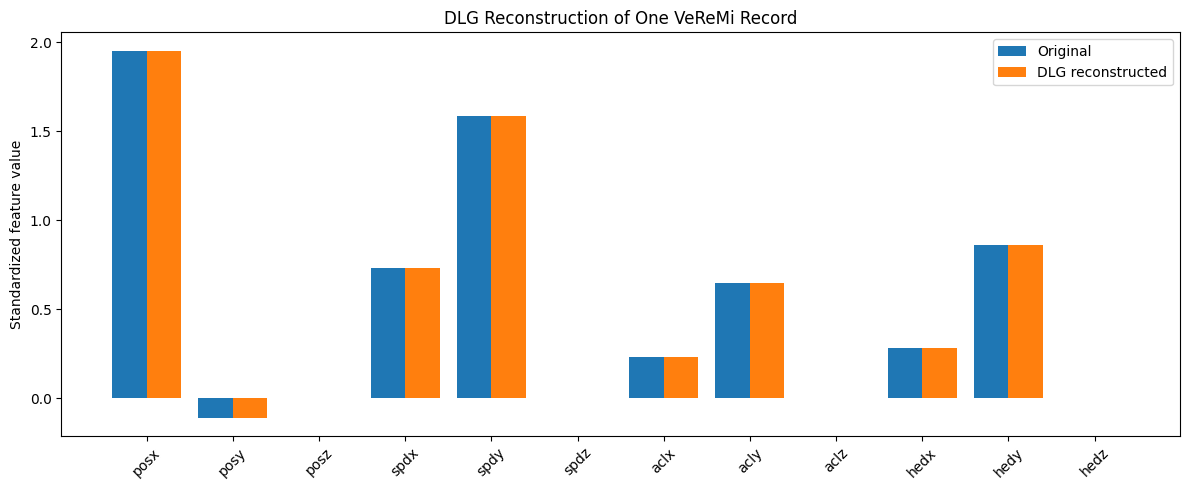

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
import matplotlib.pyplot as plt

positions = np.arange(len(FEATURES))
width = 0.4

plt.figure(figsize=(12, 5))
plt.bar(positions - width / 2, original, width, label="Original")
plt.bar(positions + width / 2, reconstructed, width, label="DLG reconstructed")

plt.xticks(positions, FEATURES, rotation=45)
plt.ylabel("Standardized feature value")
plt.title("DLG Reconstruction of One VeReMi Record")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:

import torch
import torch.nn.functional as F
import numpy as np

# Differential privacy settings
MAX_GRAD_NORM = 1.0
NOISE_MULTIPLIER = 1.0

def dp_sgd_train_epoch(model, X_tensor, y_tensor, optimizer,
                       batch_size=32, max_grad_norm=MAX_GRAD_NORM,
                       noise_multiplier=NOISE_MULTIPLIER):

    model.train()
    total_loss = 0.0
    n = len(X_tensor)

    for start in range(0, n, batch_size):
        xb = X_tensor[start:start + batch_size].to(DEVICE)
        yb = y_tensor[start:start + batch_size].to(DEVICE)
        actual_batch_size = len(xb)

        params = [p for p in model.parameters() if p.requires_grad]
        clipped_grad_sums = [torch.zeros_like(p) for p in params]

        for i in range(actual_batch_size):
            model.zero_grad(set_to_none=True)

            logits = model(xb[i:i+1])
            loss = F.cross_entropy(logits, yb[i:i+1])

            per_example_grads = torch.autograd.grad(loss, params)

            # Calculate this example's overall gradient norm
            grad_norm = torch.sqrt(
                sum(torch.sum(g.detach() ** 2) for g in per_example_grads)
            )

            # Clip the example's gradients to the maximum norm
            clip_factor = torch.clamp(
                max_grad_norm / (grad_norm + 1e-6), max=1.0
            )

            for acc, grad in zip(clipped_grad_sums, per_example_grads):
                acc.add_(grad.detach() * clip_factor)

            total_loss += loss.item()

        optimizer.zero_grad(set_to_none=True)

        # Add Gaussian noise to the summed clipped gradients,
        # then average over the batch
        for param, grad_sum in zip(params, clipped_grad_sums):
            noise = torch.randn_like(grad_sum) * (
                noise_multiplier * max_grad_norm
            )
            param.grad = (grad_sum + noise) / actual_batch_size

        optimizer.step()

    return total_loss / n

print("DP-SGD training function is ready.")


DP-SGD training function is ready.


In [ ]:

initial_dp_model = VeReMiModel()

dp_strategy = SaveModelFedAvg(
    fraction_fit=1.0,
    fraction_evaluate=1.0,
    min_fit_clients=NUM_CLIENTS,
    min_evaluate_clients=NUM_CLIENTS,
    min_available_clients=NUM_CLIENTS,
    initial_parameters=fl.common.ndarrays_to_parameters(
        get_parameters(initial_dp_model)
    ),
    evaluate_metrics_aggregation_fn=weighted_accuracy,
)

dp_history = fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=NUM_CLIENTS,
    config=fl.server.ServerConfig(num_rounds=3),
    strategy=dp_strategy,
    client_resources={"num_cpus": 1, "num_gpus": 0},
)

print("\nDP federated training finished.")
print("DP distributed loss:", dp_history.losses_distributed)
print("DP distributed metrics:", dp_history.metrics_distributed)


	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=3, no round_timeout
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
2026-10-11 05:09:06,409	INFO worker.py:2012 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'CPU': 2.0, 'node:172.28.0.12': 1.0, 'node:__internal_head__': 1.0, 'ob

(ClientAppActor pid=6499) Client 0 | Training loss: 1.1528
(ClientAppActor pid=6499) Client 1 | Training loss: 1.1525
Saved global model after round 1


(ClientAppActor pid=6499) 
(ClientAppActor pid=6499)         
(ClientAppActor pid=6500) 
(ClientAppActor pid=6500)         
INFO :      aggregate_evaluate: received 3 results and 0 failures
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 3 clients (out of 3)
(ClientAppActor pid=6500) 
(ClientAppActor pid=6500)         
(ClientAppActor pid=6500) 
(ClientAppActor pid=6500)         
INFO :      aggregate_fit: received 3 results and 0 failures
INFO :      configure_evaluate: strategy sampled 3 clients (out of 3)
(ClientAppActor pid=6499) 
(ClientAppActor pid=6499)         
(ClientAppActor pid=6500) 
(ClientAppActor pid=6500)         
INFO :      aggregate_evaluate: received 3 results and 0 failures
INFO :      
INFO :      [ROUND 3]
INFO :      configure_fit: strategy sampled 3 clients (out of 3)
(ClientAppActor pid=6499) 
(ClientAppActor pid=6499)         
(ClientAppActor pid=6500) 
(ClientAppActor pid=6500)         
(ClientAppActor pid=6500) 
(ClientAppActo

Saved global model after round 2
Saved global model after round 3


(ClientAppActor pid=6499) 
(ClientAppActor pid=6499)         
(ClientAppActor pid=6500) 
(ClientAppActor pid=6500)         
(ClientAppActor pid=6500) 
(ClientAppActor pid=6500)         
INFO :      aggregate_evaluate: received 3 results and 0 failures
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 3 round(s) in 22.73s
INFO :      	History (loss, distributed):
INFO :      		round 1: 1.1408005952835083
INFO :      		round 2: 1.1163636445999146
INFO :      		round 3: 1.0932811498641968
INFO :      	History (metrics, distributed, evaluate):
INFO :      	{'accuracy': [(1, 0.11999999731779099),
INFO :      	              (2, 0.16500000655651093),
INFO :      	              (3, 0.35499998927116394)]}
INFO :      



DP federated training finished.
DP distributed loss: [(1, 1.1408005952835083), (2, 1.1163636445999146), (3, 1.0932811498641968)]
DP distributed metrics: {'accuracy': [(1, 0.11999999731779099), (2, 0.16500000655651093), (3, 0.35499998927116394)]}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:

from sklearn.metrics import classification_report, confusion_matrix

dp_model = VeReMiModel().to(DEVICE)

dp_parameters = fl.common.parameters_to_ndarrays(
    dp_strategy.final_parameters
)
set_parameters(dp_model, dp_parameters)
dp_model.eval()

with torch.no_grad():
    test_tensor = torch.tensor(X_test, dtype=torch.float32).to(DEVICE)
    logits = dp_model(test_tensor)
    dp_predictions = logits.argmax(dim=1).cpu().numpy()

dp_accuracy = np.mean(dp_predictions == y_test)

print(f"DP model test accuracy: {dp_accuracy:.2%}")
print("\nClassification report:")
print(classification_report(
    y_test,
    dp_predictions,
    zero_division=0
))
print("Confusion matrix:")
print(confusion_matrix(y_test, dp_predictions))


DP model test accuracy: 35.50%

Classification report:
              precision    recall  f1-score   support

           0       0.67      0.51      0.58       117
           1       0.07      0.04      0.05        56
           2       0.11      0.33      0.16        27

    accuracy                           0.35       200
   macro avg       0.28      0.29      0.26       200
weighted avg       0.43      0.35      0.38       200

Confusion matrix:
[[60 20 37]
 [17  2 37]
 [12  6  9]]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:

import torch
import torch.nn.functional as F
import numpy as np
from sklearn.metrics import mean_squared_error

# Use the trained DP model and the same record as before
attack_model = dp_model
attack_model.eval()

params = tuple(p for p in attack_model.parameters()
               if p.requires_grad)

# Calculate the selected record's gradients
attack_model.zero_grad(set_to_none=True)
loss = F.cross_entropy(attack_model(x_true), y_true)
grads = torch.autograd.grad(loss, params)

# Clip the full per-example gradient
grad_norm = torch.sqrt(sum(torch.sum(g.detach() ** 2) for g in grads))
clip_factor = torch.clamp(MAX_GRAD_NORM / (grad_norm + 1e-6), max=1.0)

clipped_grads = [g.detach() * clip_factor for g in grads]

# Add Gaussian noise to the clipped gradient
torch.manual_seed(123)
dp_observed_gradients = [
    g + torch.randn_like(g) * (NOISE_MULTIPLIER * MAX_GRAD_NORM)
    for g in clipped_grads
]

print("Original gradient norm:", grad_norm.item())
print("Clipped gradient norm:",
      torch.sqrt(sum(torch.sum(g ** 2) for g in clipped_grads)).item())
print("Protected gradient created.")


Original gradient norm: 1.0869587659835815
Clipped gradient norm: 0.9999991655349731
Protected gradient created.


In [ ]:

torch.manual_seed(42)

dummy_x_dp = torch.randn_like(x_true, requires_grad=True)
optimizer_dp = torch.optim.Adam([dummy_x_dp], lr=0.05)

for step in range(2000):
    optimizer_dp.zero_grad()

    dummy_logits = attack_model(dummy_x_dp)
    dummy_loss = F.cross_entropy(dummy_logits, y_true)

    dummy_grads = torch.autograd.grad(
        dummy_loss, params, create_graph=True
    )

    # Apply the same clipping operation to the attacker's candidate gradient
    dummy_norm = torch.sqrt(
        sum(torch.sum(g ** 2) for g in dummy_grads)
    )
    dummy_factor = torch.clamp(
        MAX_GRAD_NORM / (dummy_norm + 1e-6), max=1.0
    )
    dummy_clipped = [g * dummy_factor for g in dummy_grads]

    matching_loss = sum(
        torch.sum((g - target) ** 2)
        for g, target in zip(dummy_clipped, dp_observed_gradients)
    )

    matching_loss.backward()
    optimizer_dp.step()

    if step % 400 == 0 or step == 1999:
        print(f"Step {step}: matching loss = {matching_loss.item():.6f}")

# Measure reconstruction quality
original = x_true.detach().cpu().numpy().ravel()
reconstructed_dp = dummy_x_dp.detach().cpu().numpy().ravel()

mse_dp = mean_squared_error(original, reconstructed_dp)
mae_dp = np.mean(np.abs(original - reconstructed_dp))
cos_dp = np.dot(original, reconstructed_dp) / (
    np.linalg.norm(original) * np.linalg.norm(reconstructed_dp) + 1e-12
)

print("\n--- DLG with clipped and noisy gradients ---")
print(f"Feature MSE: {mse_dp:.6f}")
print(f"Feature MAE: {mae_dp:.6f}")
print(f"Cosine similarity: {cos_dp:.6f}")


Step 0: matching loss = 992.900146
Step 400: matching loss = 989.255005
Step 800: matching loss = 988.537354
Step 1200: matching loss = 988.914856
Step 1600: matching loss = 989.107117
Step 1999: matching loss = 988.631897

--- DLG with clipped and noisy gradients ---
Feature MSE: 3.169038
Feature MAE: 1.499041
Cosine similarity: 0.378502


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


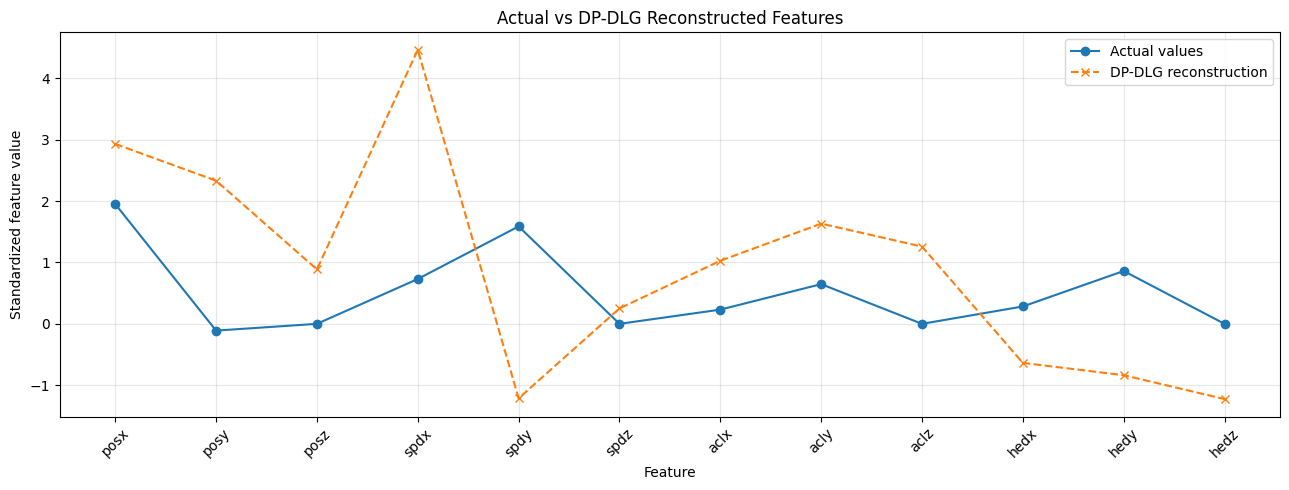

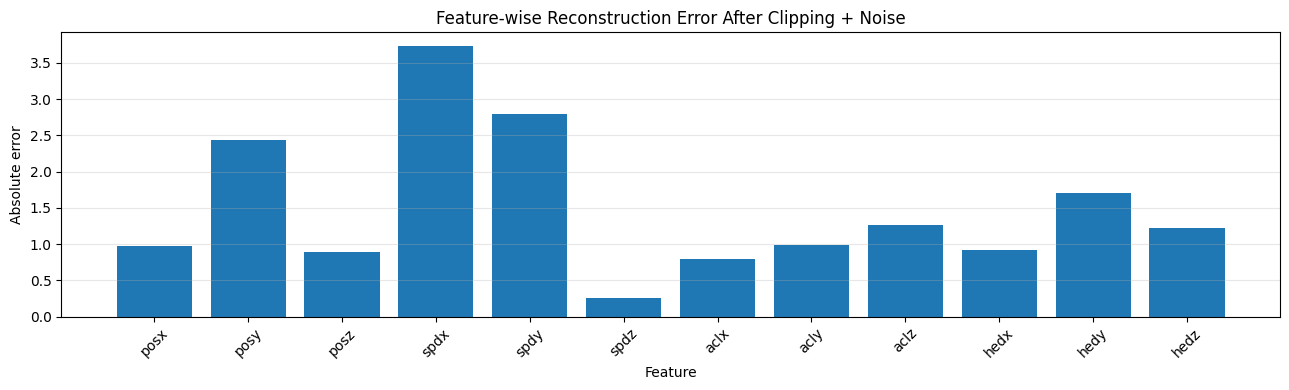

MSE: 3.169038
MAE: 1.4990411
Maximum absolute error: 3.7365355


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

actual = x_true.detach().cpu().numpy().ravel()
reconstructed = dummy_x_dp.detach().cpu().numpy().ravel()
errors = np.abs(actual - reconstructed)

feature_names = [
    "posx", "posy", "posz",
    "spdx", "spdy", "spdz",
    "aclx", "acly", "aclz",
    "hedx", "hedy", "hedz"
]

plt.figure(figsize=(13, 5))
plt.plot(feature_names, actual, marker="o", label="Actual values")
plt.plot(feature_names, reconstructed, marker="x",
         linestyle="--", label="DP-DLG reconstruction")
plt.xlabel("Feature")
plt.ylabel("Standardized feature value")
plt.title("Actual vs DP-DLG Reconstructed Features")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(13, 4))
plt.bar(feature_names, errors)
plt.xlabel("Feature")
plt.ylabel("Absolute error")
plt.title("Feature-wise Reconstruction Error After Clipping + Noise")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("MSE:", np.mean((actual - reconstructed) ** 2))
print("MAE:", np.mean(errors))
print("Maximum absolute error:", np.max(errors))

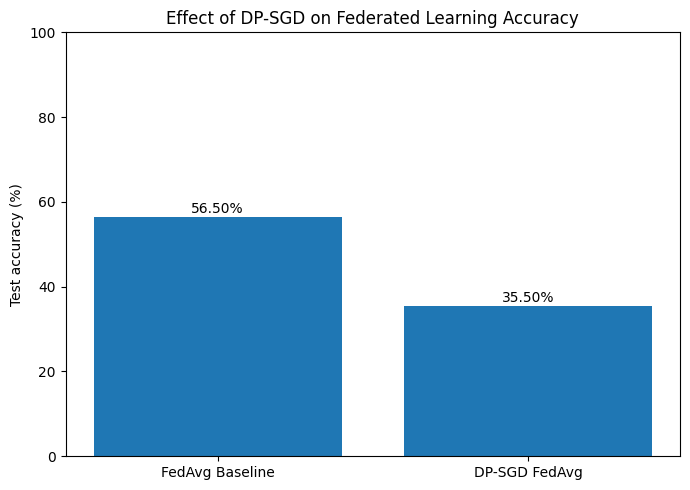

Accuracy change: -21.00 percentage points


In [ ]:
models = ["FedAvg Baseline", "DP-SGD FedAvg"]
accuracies = [56.50, 35.50]

plt.figure(figsize=(7, 5))
bars = plt.bar(models, accuracies)

plt.ylabel("Test accuracy (%)")
plt.title("Effect of DP-SGD on Federated Learning Accuracy")
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

print(f"Accuracy change: {accuracies[1] - accuracies[0]:.2f} percentage points")